# Macro check: are the interest rates realistic? (World Bank API)

**Question.** Do the interest rates in the data, and the rates our pipelines suggest, look like real-world loan pricing?

**Idea.** Every loan rate = **benchmark** (the economy's base rate, the same for everyone at a given time) + **premium** (the extra charged for *this* borrower's risk). Real risk-based pricing should give premiums that are **positive** and **rise with risk** (grade A → G, or low → high PD). Comparing premiums rather than raw rates removes the effect of the economy and isolates the risk pricing.

**Data from the API** (`requests`, World Bank, no key needed), United States, yearly:
- **Lending interest rate** (`FR.INR.LEND`): for the US this is the **bank prime rate**, the rate banks charge their best customers.
- **Inflation, consumer prices** (`FP.CPI.TOTL.ZG`).

**Assumptions and limits (stated up front)**
- The dataset has **no loan dates**, so each loan's own year is unknown. We infer a **plausible period** and use its average prime rate as the benchmark, and we also show the premiums year by year.
- The dataset's country is **not documented**; its structure (grades A–G, home-ownership categories, a $35,000 loan cap) matches US marketplace lending, so **US** indicators are used.
- The prime rate is a floor, not the rate on personal loans, so the meaningful comparison is the **premium over it**, not equality.

This is a **descriptive check** done after the final test: nothing is retrained or re-chosen. The models' suggested rates are those from notebook 11 (test set, approved applicants only, since only they are offered a rate).

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import DATA, REPORTS, TARGET

FIG = REPORTS / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
GRADES = list("ABCDEFG")
GRADE_COLORS = dict(zip(GRADES, sns.color_palette("rocket_r", 9)[1:8]))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}.png")

## Step 1: Download the macro data (World Bank API)

The API is sometimes slow, so the request is retried; the result is cached in `data/processed/macro_worldbank_usa.csv` and the cache is used if the API is unreachable.

In [2]:
INDICATORS = {"FR.INR.LEND": "lending rate (prime, %)", "FP.CPI.TOTL.ZG": "inflation (%)"}
CACHE = DATA / "macro_worldbank_usa.csv"

def fetch(indicator, country="USA", start=2000, end=2025, tries=4):
    url = f"https://api.worldbank.org/v2/country/{country}/indicator/{indicator}"
    for attempt in range(tries):
        try:
            r = requests.get(url, params={"format": "json", "date": f"{start}:{end}", "per_page": 100}, timeout=90)
            r.raise_for_status()
            rows = r.json()[1]
            return pd.Series({int(x["date"]): x["value"] for x in rows}, dtype="float64").sort_index()
        except Exception as e:
            print(f"  {indicator}: attempt {attempt + 1} failed ({type(e).__name__}), retrying")
            time.sleep(5)
    raise RuntimeError(f"World Bank API unreachable for {indicator}")

try:
    macro = pd.DataFrame({name: fetch(code) for code, name in INDICATORS.items()})
    macro.index.name = "year"
    macro.to_csv(CACHE)
    print("downloaded from the World Bank API and cached")
except RuntimeError as e:
    macro = pd.read_csv(CACHE, index_col="year")
    print(f"{e}: using the cached copy")
display(macro.round(2).T)
print("The US prime-rate series is published up to", int(macro["lending rate (prime, %)"].last_valid_index()))

downloaded from the World Bank API and cached


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
"lending rate (prime, %)",9.23,6.92,4.68,4.12,4.34,6.19,7.96,8.05,5.09,3.25,...,3.51,4.10,4.90,5.28,3.54,3.25,NaN,NaN,NaN,NaN
inflation (%),3.38,2.83,1.59,2.27,2.68,3.39,3.23,2.85,3.84,-0.36,...,1.26,2.13,2.44,1.81,1.23,4.70,8.0,4.12,2.95,NaN


The US prime-rate series is published up to 2021


## Step 2: The rates in the data, by grade

All cleaned loans with a recorded rate (training + test sets together: this describes the **data**, not a model).

In [3]:
data = pd.concat([pd.read_csv(DATA / "train.csv"), pd.read_csv(DATA / "test.csv")], ignore_index=True)
data = data[data["loan_int_rate"].notna()]
grade_tab = data.groupby("loan_grade").agg(loans=("loan_int_rate", "size"), mean_rate=("loan_int_rate", "mean"),
                                           p5=("loan_int_rate", lambda s: s.quantile(0.05)),
                                           p95=("loan_int_rate", lambda s: s.quantile(0.95)),
                                           default_rate=(TARGET, "mean"))
display(grade_tab.round(3))
cheapest = data["loan_int_rate"].quantile(0.05)
print(f"all loans: mean rate {data['loan_int_rate'].mean():.2f}%, cheapest 5% of loans below {cheapest:.2f}%")

,loans,mean_rate,p5,p95,default_rate
loan_grade,,,,,
A,9712,7.329,5.420,8.940,0.100
B,9335,10.996,9.630,12.530,0.163
C,5807,13.465,11.780,15.230,0.208
D,3308,15.360,13.360,17.270,0.595
E,880,17.008,14.928,19.392,0.649
F,214,18.609,15.960,21.119,0.701
G,59,20.252,18.828,22.110,0.983


all loans: mean rate 11.02%, cheapest 5% of loans below 6.03%


## Step 3: The plausible period and the benchmark

An unsecured personal loan is almost never cheaper than the prime rate. So a year is **plausible** for these loans only if that year's prime rate is **below the cheapest loans in the data** (the 5th percentile of all rates). The **benchmark** is the average prime rate over the plausible years. This is an inference, not a fact about the data.

plausible years (prime rate below 6.03%): [2002, 2003, 2004, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]
implausible years (prime rate above the cheapest loans): [2000, 2001, 2005, 2006, 2007]
benchmark = average prime rate over the plausible years = 3.86%;  average inflation then = 1.98%


saved reports/figures/macro_context.png


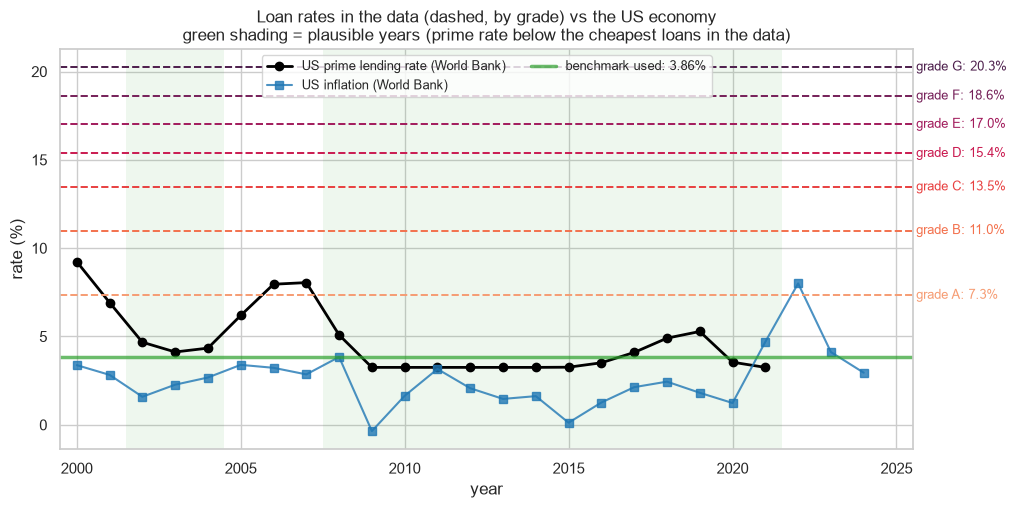

In [4]:
prime = macro["lending rate (prime, %)"].dropna()
plausible = prime[prime < cheapest].index.tolist()
BENCH = prime.loc[plausible].mean()
INFL = macro.loc[plausible, "inflation (%)"].mean()
print(f"plausible years (prime rate below {cheapest:.2f}%): {plausible}")
print(f"implausible years (prime rate above the cheapest loans): {[y for y in prime.index if y not in plausible]}")
print(f"benchmark = average prime rate over the plausible years = {BENCH:.2f}%;  average inflation then = {INFL:.2f}%")

fig, ax = plt.subplots(figsize=(11, 5.2))
for y in plausible:
    ax.axvspan(y - 0.5, y + 0.5, color="tab:green", alpha=0.08, lw=0)
ax.plot(prime.index, prime.values, marker="o", color="black", lw=2, label="US prime lending rate (World Bank)")
ax.plot(macro.index, macro["inflation (%)"], marker="s", color="tab:blue", lw=1.5, alpha=0.8, label="US inflation (World Bank)")
for g in GRADES:
    ax.axhline(grade_tab.loc[g, "mean_rate"], color=GRADE_COLORS[g], ls="--", lw=1.4)
    ax.text(macro.index.max() + 0.6, grade_tab.loc[g, "mean_rate"], f"grade {g}: {grade_tab.loc[g, 'mean_rate']:.1f}%",
            va="center", fontsize=9, color=GRADE_COLORS[g])
ax.axhline(BENCH, color="tab:green", lw=2.5, alpha=0.7, label=f"benchmark used: {BENCH:.2f}%")
ax.set_xlim(macro.index.min() - 0.5, macro.index.max() + 0.5)
ax.set_xlabel("year"); ax.set_ylabel("rate (%)")
ax.set_title("Loan rates in the data (dashed, by grade) vs the US economy\n"
             "green shading = plausible years (prime rate below the cheapest loans in the data)")
ax.legend(loc="upper center", fontsize=9, ncol=2)
save(fig, "macro_context"); plt.show()

## Step 4: Risk premiums in the data

Premium = each loan's rate − benchmark. If the data reflects real risk-based pricing, the premium should rise from grade A to G, and default rates should rise with it.

saved reports/figures/premium_by_grade_data.png


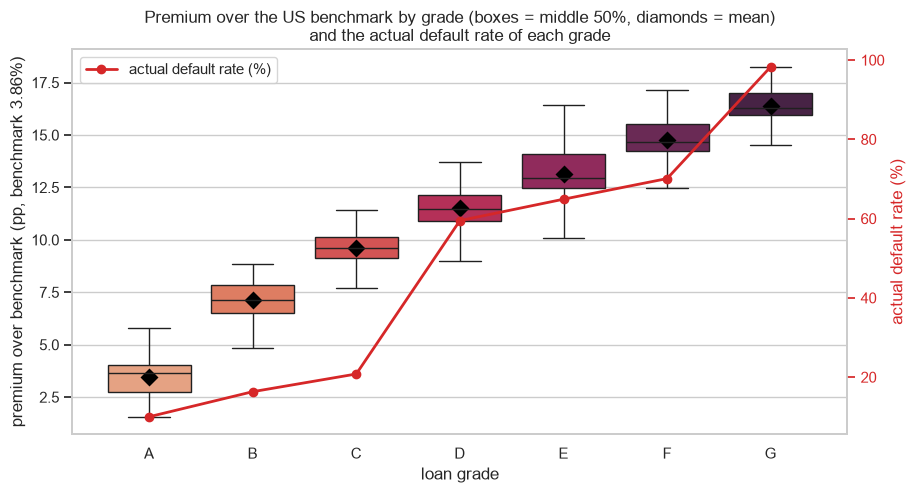

,count,mean,25%,50%,75%,real rate (rate - inflation),default rate
loan_grade,,,,,,,
A,9712.0,3.47,2.76,3.63,4.04,5.35,0.10
B,9335.0,7.14,6.50,7.13,7.85,9.02,0.16
C,5807.0,9.61,9.12,9.62,10.13,11.48,0.21
D,3308.0,11.50,10.88,11.45,12.14,13.38,0.59
E,880.0,13.15,12.46,12.96,14.07,15.03,0.65
F,214.0,14.75,14.23,14.68,15.52,16.63,0.70
G,59.0,16.39,15.96,16.30,17.02,18.27,0.98


In [5]:
data["premium"] = data["loan_int_rate"] - BENCH
fig, ax1 = plt.subplots(figsize=(10, 5))
sns.boxplot(data=data, x="loan_grade", y="premium", order=GRADES, hue="loan_grade", palette=GRADE_COLORS,
            legend=False, showfliers=False, ax=ax1)
sns.pointplot(data=data, x="loan_grade", y="premium", order=GRADES, estimator="mean", errorbar=None,
              color="black", markers="D", linestyles="", ax=ax1)
ax1.set_xlabel("loan grade"); ax1.set_ylabel(f"premium over benchmark (pp, benchmark {BENCH:.2f}%)")
ax2 = ax1.twinx()
ax2.plot(range(len(GRADES)), grade_tab.loc[GRADES, "default_rate"] * 100, color="tab:red", marker="o", lw=2,
         label="actual default rate (%)")
ax2.set_ylabel("actual default rate (%)", color="tab:red"); ax2.tick_params(axis="y", colors="tab:red"); ax2.grid(False)
ax2.legend(loc="upper left")
ax1.set_title("Premium over the US benchmark by grade (boxes = middle 50%, diamonds = mean)\nand the actual default rate of each grade")
save(fig, "premium_by_grade_data"); plt.show()

prem_tab = data.groupby("loan_grade")["premium"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "mean", "25%", "50%", "75%"]]
prem_tab["real rate (rate - inflation)"] = grade_tab["mean_rate"] - INFL
prem_tab["default rate"] = grade_tab["default_rate"]
display(prem_tab.round(2))

## Step 5: Our pipelines' suggested rates (test set, approved applicants)

The rates the final system would offer to **approved** test applicants (PD below the cutoff), from notebook 11, converted to premiums over the same benchmark and compared with the premiums those applicants **actually** paid.

- **Pipeline A** (grade known): compared within each grade.
- **Pipeline B** (newcomer): compared across five equal-size PD bands (lowest to highest risk among approved newcomers).

saved reports/figures/pipelineA_premium_vs_actual.png


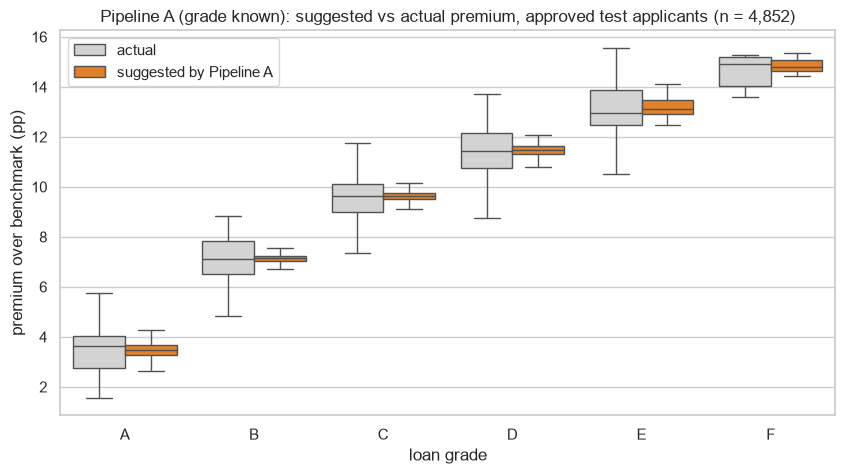

applicants                         mean premium                          \
rate      actual suggested by Pipeline A       actual suggested by Pipeline A   
grade                                                                           
A           1844                    1844         3.43                    3.47   
B           1698                    1698         7.18                    7.13   
C            932                     932         9.60                    9.63   
D            296                     296        11.44                   11.49   
E             75                      75        13.11                   13.20   
F              7                       7        14.81                   14.87   

      spread (IQR)                          
rate        actual suggested by Pipeline A  
grade                                       
A             1.26                    0.41  
B             1.34                    0.21  
C             1.11                    0.27  
D             1.39                    0.35  
E             1.39                    0.57  
F             1.18                    0.44

saved reports/figures/pipelineB_premium_vs_actual.png


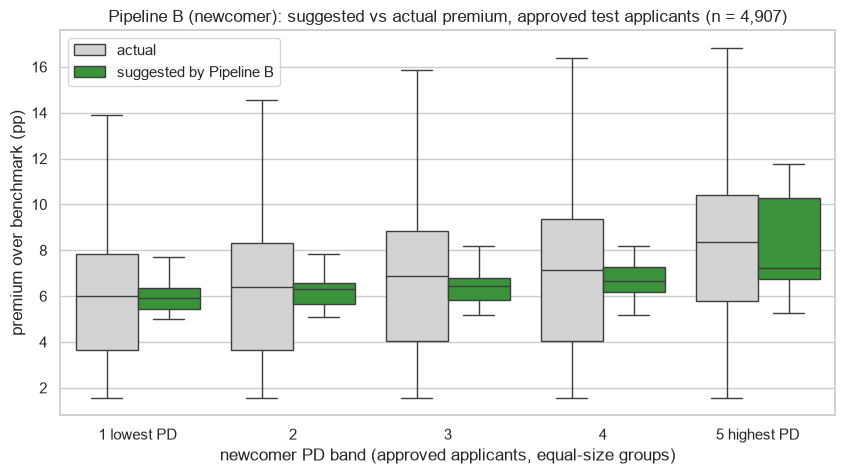

applicants                         mean premium  \
                 actual suggested by Pipeline B       actual   
PD band                                                        
1 lowest PD         983                     983         5.90   
2                   980                     980         6.27   
3                   981                     981         6.82   
4                   981                     981         7.03   
5 highest PD        982                     982         8.07   

                                     spread (IQR)                          \
             suggested by Pipeline B       actual suggested by Pipeline B   
PD band                                                                     
1 lowest PD                     6.02         4.22                    0.91   
2                               6.38         4.70                    0.91   
3                               6.72         4.80                    0.97   
4                               7.10         5.34                    1.06   
5 highest PD                    8.00         4.64                    3.57   

             PD range         
                  min    max  
PD band                       
1 lowest PD     0.002  0.024  
2               0.024  0.057  
3               0.057  0.105  
4               0.105  0.181  
5 highest PD    0.181  0.388

In [6]:
tp = pd.read_csv(DATA / "test_predictions.csv")
A, B = "Pipeline A (grade)", "Pipeline B (newcomer)"

a = tp[tp[f"approved {A}"] & tp["loan_int_rate"].notna()].copy()
long_a = pd.concat([pd.DataFrame({"grade": a["loan_grade"], "premium": a["loan_int_rate"] - BENCH, "rate": "actual"}),
                    pd.DataFrame({"grade": a["loan_grade"], "premium": a[f"suggested rate {A}"] - BENCH,
                                  "rate": "suggested by Pipeline A"})])
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=long_a, x="grade", y="premium", hue="rate", order=[g for g in GRADES if g in set(a["loan_grade"])],
            palette={"actual": "lightgrey", "suggested by Pipeline A": "tab:orange"}, showfliers=False, ax=ax)
ax.set_xlabel("loan grade"); ax.set_ylabel(f"premium over benchmark (pp)")
ax.set_title(f"Pipeline A (grade known): suggested vs actual premium, approved test applicants (n = {len(a):,})")
ax.legend(title="")
save(fig, "pipelineA_premium_vs_actual"); plt.show()
tab_a = long_a.groupby(["grade", "rate"])["premium"].agg(["count", "mean", lambda s: s.quantile(0.75) - s.quantile(0.25)])
tab_a.columns = ["applicants", "mean premium", "spread (IQR)"]
display(tab_a.unstack("rate").round(2))

b = tp[tp[f"approved {B}"] & tp["loan_int_rate"].notna()].copy()
b["PD band"] = pd.qcut(b[f"PD {B}"], 5, labels=["1 lowest PD", "2", "3", "4", "5 highest PD"])
long_b = pd.concat([pd.DataFrame({"PD band": b["PD band"], "premium": b["loan_int_rate"] - BENCH, "rate": "actual"}),
                    pd.DataFrame({"PD band": b["PD band"], "premium": b[f"suggested rate {B}"] - BENCH,
                                  "rate": "suggested by Pipeline B"})])
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=long_b, x="PD band", y="premium", hue="rate",
            palette={"actual": "lightgrey", "suggested by Pipeline B": "tab:green"}, showfliers=False, ax=ax)
ax.set_xlabel("newcomer PD band (approved applicants, equal-size groups)"); ax.set_ylabel("premium over benchmark (pp)")
ax.set_title(f"Pipeline B (newcomer): suggested vs actual premium, approved test applicants (n = {len(b):,})")
ax.legend(title="")
save(fig, "pipelineB_premium_vs_actual"); plt.show()
tab_b = long_b.groupby(["PD band", "rate"], observed=True)["premium"].agg(
    ["count", "mean", lambda s: s.quantile(0.75) - s.quantile(0.25)])
tab_b.columns = ["applicants", "mean premium", "spread (IQR)"]
pd_range = b.groupby("PD band", observed=True)[f"PD {B}"].agg(["min", "max"]).round(3)
pd_range.columns = pd.MultiIndex.from_product([["PD range"], ["min", "max"]])
display(tab_b.unstack("rate").round(2).join(pd_range))

## Step 6: Robustness: does the conclusion depend on the year?

The premium of each grade's average rate over **every** year's prime rate (2000–2021), plus the benchmark ±2 pp. Only the **level** of the premiums moves with the year; the **pattern across grades** (and the gaps between them) is identical, because the same benchmark is subtracted from every loan.

saved reports/figures/premium_by_year_heatmap.png


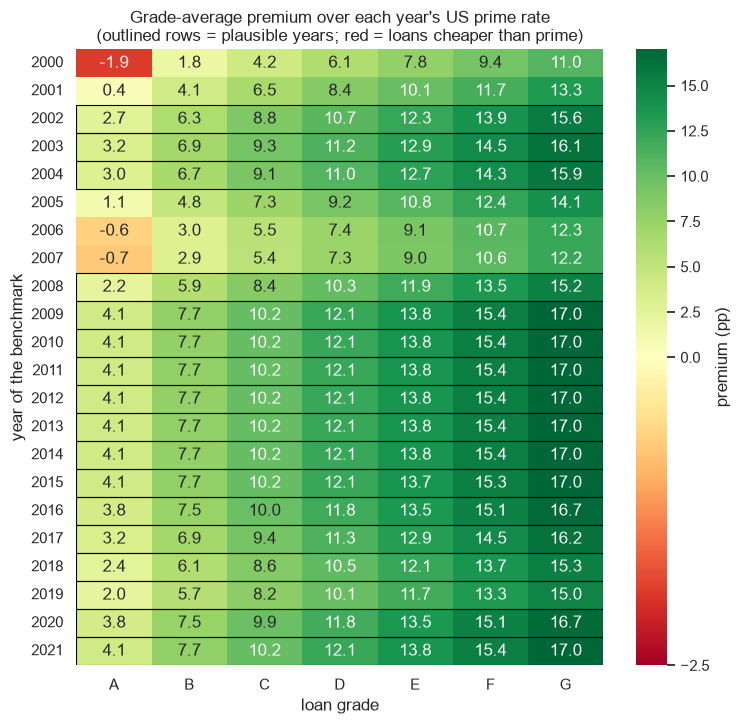

Grade-average premium for three benchmark levels:


,benchmark 1.86%,benchmark 3.86%,benchmark 5.86%,gap to grade A (any benchmark)
loan_grade,,,,
A,5.47,3.47,1.47,0.00
B,9.14,7.14,5.14,3.67
C,11.61,9.61,7.61,6.14
D,13.50,11.50,9.50,8.03
E,15.15,13.15,11.15,9.68
F,16.75,14.75,12.75,11.28
G,18.39,16.39,14.39,12.92


In [7]:
heat = pd.DataFrame({g: grade_tab.loc[g, "mean_rate"] - prime for g in GRADES})
heat.index.name = "year"
fig, ax = plt.subplots(figsize=(8.5, 8))
from matplotlib.colors import TwoSlopeNorm
# separate scales below and above zero, so negative premiums (loans cheaper than prime) show clearly red
sns.heatmap(heat, annot=True, fmt=".1f", cmap="RdYlGn", norm=TwoSlopeNorm(vmin=-2.5, vcenter=0, vmax=heat.values.max()),
            cbar_kws={"label": "premium (pp)"}, ax=ax)
for i, y in enumerate(heat.index):
    if y in plausible:
        ax.add_patch(plt.Rectangle((0, i), len(GRADES), 1, fill=False, edgecolor="black", lw=0.8))
ax.set_xlabel("loan grade"); ax.set_ylabel("year of the benchmark")
ax.set_title("Grade-average premium over each year's US prime rate\n(outlined rows = plausible years; red = loans cheaper than prime)")
save(fig, "premium_by_year_heatmap"); plt.show()

sens = pd.DataFrame({f"benchmark {BENCH + d:.2f}%": grade_tab["mean_rate"] - (BENCH + d) for d in [-2, 0, 2]})
sens["gap to grade A (any benchmark)"] = grade_tab["mean_rate"] - grade_tab.loc["A", "mean_rate"]
print("Grade-average premium for three benchmark levels:")
display(sens.round(2))

## Step 7: Conclusions (for the website)

The cell below prints the key numbers; the text summarises what the charts show.

In [8]:
ga, gg = prem_tab.loc["A", "mean"], prem_tab.loc["G", "mean"]
sa = tab_a.unstack("rate")
sb = tab_b.unstack("rate")
print(f"Benchmark: average US prime rate {BENCH:.2f}% over the {len(plausible)} plausible years {plausible} "
      f"(all years 2000-2021 except {[y for y in prime.index if y not in plausible]}); inflation then {INFL:.2f}%.")
print(f"Data: premiums rise from grade A ({ga:+.1f} pp) to grade G ({gg:+.1f} pp); default rates rise from "
      f"{grade_tab.loc['A', 'default_rate']:.0%} to {grade_tab.loc['G', 'default_rate']:.0%}.")
print(f"Pipeline A: suggested mean premium per grade tracks the actual one "
      f"(grade A {sa.loc['A', ('mean premium', 'suggested by Pipeline A')]:+.2f} vs {sa.loc['A', ('mean premium', 'actual')]:+.2f} pp).")
lo, hi = sb.index[0], sb.index[-1]
print(f"Pipeline B: suggested premium rises from {sb.loc[lo, ('mean premium', 'suggested by Pipeline B')]:+.2f} to "
      f"{sb.loc[hi, ('mean premium', 'suggested by Pipeline B')]:+.2f} pp across PD bands, while the actual premium goes from "
      f"{sb.loc[lo, ('mean premium', 'actual')]:+.2f} to {sb.loc[hi, ('mean premium', 'actual')]:+.2f} pp; "
      f"its spread within a band is {sb[('spread (IQR)', 'suggested by Pipeline B')].mean():.2f} pp vs "
      f"{sb[('spread (IQR)', 'actual')].mean():.2f} pp actual.")

Benchmark: average US prime rate 3.86% over the 17 plausible years [2002, 2003, 2004, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021] (all years 2000-2021 except [2000, 2001, 2005, 2006, 2007]); inflation then 1.98%.
Data: premiums rise from grade A (+3.5 pp) to grade G (+16.4 pp); default rates rise from 10% to 98%.
Pipeline A: suggested mean premium per grade tracks the actual one (grade A +3.47 vs +3.43 pp).
Pipeline B: suggested premium rises from +6.02 to +8.00 pp across PD bands, while the actual premium goes from +5.90 to +8.07 pp; its spread within a band is 1.48 pp vs 4.74 pp actual.


**What the check shows**

1. **The data's rates are realistic for a low-rate era.** Every grade sits above the US prime rate in the plausible years, and the premium rises steadily from grade A to G, as risk-based pricing should; default rates rise with it.
2. **The loans most plausibly come from lower-rate years.** In the high-rate years (2000–01 and 2005–07, prime rate 6–9%) the cheapest loans in the data would have been below the prime rate, which is implausible; all other years from 2000–2021 are plausible.
3. **Pipeline A prices like the lender.** Its suggested premiums follow the actual ones grade by grade, with a narrower spread within each grade (it explains the grade but only part of the person-to-person differences).
4. **Pipeline B gets the average right but not the individual.** Its average suggested premium in each PD band matches the actual average (both rise with PD), so on average risk is priced correctly. But within each band its suggestions are several times less spread out than the real rates, so it cannot tell apart borrowers with a similar PD who were actually charged very different rates: individual newcomers can be over- or under-charged by several points (this is the ±2.7 pp error and the low R² seen in notebooks 07 and 11).
5. **Robust to the unknown year:** the benchmark only shifts the level of all premiums; the pattern across grades and PD bands is unchanged.

**Limitations:** no loan dates (the benchmark is an inferred period average); the country is assumed to be the US; the prime rate is a floor rather than the market rate for personal loans; the World Bank US lending-rate series ends in 2021.